# Experiment analysis

Builds the tables and figure of the Results section from the CSVs written by
`scripts/run_experiments.py` into `scripts/experiments/`.


In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

root = Path.cwd()
while not (root / "compose.yaml").exists():
    root = root.parent
EXP = root / "scripts" / "experiments"
FIGS = root / "docs" / "report" / "figs"

runs = pd.concat(
    [pd.read_csv(f).assign(experiment=f.parent.name)
     for f in sorted(EXP.glob("*/runs.csv"))],
    ignore_index=True,
)

faults = sorted(EXP.glob("kill-leader-*")) + sorted(EXP.glob("partition-*"))
ttr = pd.concat(
    [pd.read_csv(d / "summary.csv").assign(experiment=d.name) for d in faults],
    ignore_index=True,
)


In [6]:
# tab:perf
PERF = [
    ("No fault", 3, "baseline", "baseline"),
    ("", 5, "sweep-n5", "n5"),     # blank label: same configuration as above
    ("", 7, "sweep-n7", "n7"),
    ("50\\,ms delay", 3, "netem-d50ms", None),
    ("100\\,ms delay", 3, "netem-d100ms", None),
    ("2\\,\\% loss", 3, "netem-l2pct", None),
    ("5\\,\\% loss", 3, "netem-l5pct", None),
]


def perf_row(label, n, experiment, tag):
    df = runs[runs["experiment"] == experiment]
    if tag is not None:
        df = df[df["tag"] == tag]
    return {"config": label, "N": n,
            "ops/s": df["throughput_ops_s"].median(),
            "p50": df["p50_ms"].median(),
            "p95": df["p95_ms"].median(),
            "p99": df["p99_ms"].median()}


def fmt(v):
    return f"{v:.0f}" if v >= 100 else f"{v:.1f}"


perf = pd.DataFrame(perf_row(*spec) for spec in PERF)
display(perf.round(1))

print("% tab:perf")
for _, r in perf.iterrows():
    cells = [f"{r['ops/s']:.0f}"] + [fmt(r[c]) for c in ("p50", "p95", "p99")]
    print(f"{r['config']:18s} & {r['N']} & " + " & ".join(cells) + r" \\")


,config,N,ops/s,p50,p95,p99
0,No fault,3,1671.0,4.5,7.1,9.1
1,,5,1183.5,5.9,9.8,14.3
2,,7,954.1,7.8,13.2,18.2
3,"50\,ms delay",3,51.4,151.7,164.5,186.8
4,"100\,ms delay",3,26.0,301.8,304.1,312.4
5,"2\,\% loss",3,578.6,1.9,5.0,209.9
6,"5\,\% loss",3,222.0,1.8,207.2,374.3


% tab:perf
No fault           & 3 & 1671 & 4.5 & 7.1 & 9.1 \\
                   & 5 & 1184 & 5.9 & 9.8 & 14.3 \\
                   & 7 & 954 & 7.8 & 13.2 & 18.2 \\
50\,ms delay       & 3 & 51 & 152 & 165 & 187 \\
100\,ms delay      & 3 & 26 & 302 & 304 & 312 \\
2\,\% loss         & 3 & 579 & 1.9 & 5.0 & 210 \\
5\,\% loss         & 3 & 222 & 1.8 & 207 & 374 \\


In [7]:
# tab:recovery
FAULTS = {
    "Crash": ["kill-leader-n3", "kill-leader-n5", "kill-leader-n7"],
    "Disconnect": ["partition-n3", "partition-n5", "partition-n7"],
}
TTR = ("time_to_elect_ms", "ttr_service_ms", "ttr_replica_ms")

rows = []
for fault, experiments in FAULTS.items():
    for n, experiment in zip((3, 5, 7), experiments):
        g = ttr[ttr["experiment"] == experiment]
        rows.append({"fault": fault, "N": n,
                     **{c: f"{g[c].mean():.0f} ± {g[c].std(ddof=1):.0f}" for c in TTR}})
rec = pd.DataFrame(rows)
display(rec)

print("% tab:recovery")
for i, (fault, g) in enumerate(rec.groupby("fault", sort=False)):
    if i:
        print(r"\midrule")
    for _, r in g.iterrows():
        cells = [r[c].replace("±", r"$\pm$") for c in TTR]
        print(f"{fault if r['N'] == 3 else '':10s} & {r['N']} & " + " & ".join(cells) + r" \\")


,fault,N,time_to_elect_ms,ttr_service_ms,ttr_replica_ms
0,Crash,3,1243 ± 1089,2405 ± 1184,584 ± 152
1,Crash,5,784 ± 36,2081 ± 461,526 ± 313
2,Crash,7,774 ± 47,2574 ± 1050,633 ± 270
3,Disconnect,3,1571 ± 1380,3162 ± 1611,849 ± 447
4,Disconnect,5,911 ± 63,2494 ± 1054,1212 ± 1129
5,Disconnect,7,859 ± 30,2187 ± 27,780 ± 267


% tab:recovery
Crash      & 3 & 1243 $\pm$ 1089 & 2405 $\pm$ 1184 & 584 $\pm$ 152 \\
           & 5 & 784 $\pm$ 36 & 2081 $\pm$ 461 & 526 $\pm$ 313 \\
           & 7 & 774 $\pm$ 47 & 2574 $\pm$ 1050 & 633 $\pm$ 270 \\
\midrule
Disconnect & 3 & 1571 $\pm$ 1380 & 3162 $\pm$ 1611 & 849 $\pm$ 447 \\
           & 5 & 911 $\pm$ 63 & 2494 $\pm$ 1054 & 1212 $\pm$ 1129 \\
           & 7 & 859 $\pm$ 30 & 2187 $\pm$ 27 & 780 $\pm$ 267 \\


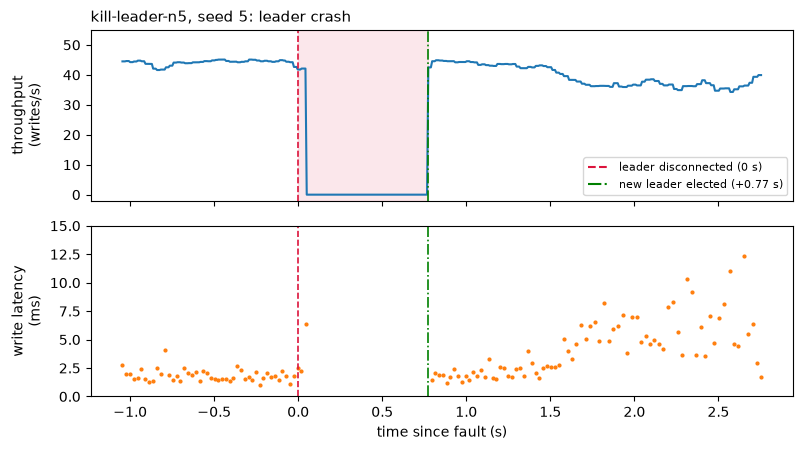

In [8]:
# fig:leader-fault
SCENARIO, SEED = "kill-leader-n5", 5

row = pd.read_csv(EXP / SCENARIO / "summary.csv").set_index("seed").loc[SEED]
probe = pd.read_csv(EXP / SCENARIO / f"probe-{SEED}.csv").sort_values("end_ns")
fault = row["fault_unix_ms"]
t_elect = row["time_to_elect_ms"] / 1000
t_svc = row["ttr_service_ms"] / 1000

# write rate on a regular grid; gaps longer than 150 ms mean no write completed
probe["t_end"] = (probe["end_ns"] / 1e6 - fault) / 1000
dt = probe["t_end"].diff()
rate = (1 / dt.where(dt <= 0.15)).rolling(5, min_periods=1, center=True).mean()
t_grid = np.linspace(probe["t_end"].iloc[0], probe["t_end"].iloc[-1], 500)
idx = np.searchsorted(probe["t_end"], t_grid, side="right").clip(1, len(probe) - 1)
rate = np.where(dt.to_numpy()[idx] > 0.15, 0.0, rate.to_numpy()[idx])

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
top.plot(t_grid, rate, color="C0", lw=1.5)
top.axvspan(0, t_svc, color="crimson", alpha=0.10)
top.set(ylabel="throughput\n(writes/s)", ylim=(-2, 55))
top.set_title(f"{SCENARIO}, seed {SEED}: leader crash", loc="left", fontsize=11)

bottom.plot(probe["t_end"], probe["lat_ms"], ".", ms=4, color="C1")
bottom.set(xlabel="time since fault (s)", ylabel="write latency\n(ms)", ylim=(0, 15))

for ax in (top, bottom):
    ax.axvline(0, color="crimson", ls="--", lw=1.2)
    ax.axvline(t_elect, color="green", ls="-.", lw=1.2)

top.legend(handles=[
    Line2D([], [], color="crimson", ls="--", label="leader disconnected (0 s)"),
    Line2D([], [], color="green", ls="-.", label=f"new leader elected (+{t_elect:.2f} s)"),
], loc="lower right", fontsize=8)

fig.align_ylabels((top, bottom))
fig.tight_layout()
fig.savefig(FIGS / "leader-fault-timeline.pdf", bbox_inches="tight")
plt.show()
